# HPC Dataset — Full Data Observation and Exploratory Analysis (Before Cleaning)

**Purpose:** Inspect the raw HPC monitoring dataset before making any changes to it. This notebook is designed to help assess whether the data can support:

1. Learning normal HPC cluster behaviour.
2. Detecting anomalous behaviour.
3. Predicting node or cluster failures before they occur.

**Important:** This is an observation and exploratory data analysis (EDA) notebook. It does **not** clean, impute, normalize, remove outliers, relabel, or overwrite the source dataset. Any flagged records are reported for investigation only.

## How to use

1. Place `raw_hpc_full.parquet` in your Windows **Downloads** folder.
2. Run the cells from top to bottom.
3. If the file has a different name or location, update `DATA_PATH` in the configuration cell.
4. If `pyarrow` is missing, run the installation cell and restart the kernel if prompted.

The notebook uses Pandas, PyArrow, Matplotlib and Seaborn.

## 1. Install and import dependencies

If the imports fail because a package is missing, uncomment and run the installation command below. Internet access may be required.

In [1]:
# Run only if dependencies are missing:
# %pip install pandas pyarrow matplotlib seaborn numpy

In [2]:
from pathlib import Path
import os
import sys
import warnings
import importlib.util

warnings.filterwarnings("ignore", category=FutureWarning)

required = ["pandas", "pyarrow", "matplotlib", "seaborn", "numpy"]
missing = [pkg for pkg in required if importlib.util.find_spec(pkg) is None]

if missing:
    print("Missing packages:", missing)
    print("Install them with:")
    print("%pip install " + " ".join(missing))
else:
    print("All required packages are available.")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", 150)
pd.set_option("display.max_rows", 100)
pd.set_option("display.max_colwidth", 120)

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (12, 5)
plt.rcParams["axes.titlesize"] = 13
plt.rcParams["axes.labelsize"] = 10

print("Python:", sys.version.split()[0])
print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("Matplotlib:", plt.matplotlib.__version__)
print("Seaborn:", sns.__version__)

All required packages are available.
Python: 3.12.3
Pandas: 3.1.1
NumPy: 2.5.4
Matplotlib: 3.11.2
Seaborn: 0.13.2


## 2. Load the raw Parquet file from the remote Jupyter server

This notebook runs on a remote server, not on your Windows computer. The dataset is expected at `/shared/collab/raw_hpc_full.parquet`.

If you uploaded it to another server directory, change `DATA_PATH` in the loading cell. The original Parquet file is read only and is never overwritten.

In [3]:
from pathlib import Path
import pandas as pd

DATA_PATH = Path("/shared/collab/raw_hpc_full.parquet")

if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Dataset not found: {DATA_PATH}\n"
        "Upload raw_hpc_full.parquet to /shared/collab or update DATA_PATH."
    )

print("Dataset path:", DATA_PATH)
print("File exists:", DATA_PATH.exists())
print(f"File size: {DATA_PATH.stat().st_size / (1024**2):.2f} MB")

df_raw = pd.read_parquet(DATA_PATH, engine="pyarrow")

print("\nDataset loaded successfully")
print("Rows:", f"{len(df_raw):,}")
print("Columns:", df_raw.shape[1])
display(df_raw.head())

Dataset path: /shared/collab/raw_hpc_full.parquet
File exists: True
File size: 45.42 MB

Dataset loaded successfully
Rows: 49,616,574
Columns: 5


,timestamp,node_id,metric,labels,value
0,1.792282e+09,compute002,node_cpu_seconds_total,__name__=node_cpu_seconds_total|cpu=0|instance=10.100.0.167:9100|job=node-exporter|mode=idle,86039.33
1,1.792282e+09,compute002,node_cpu_seconds_total,__name__=node_cpu_seconds_total|cpu=0|instance=10.100.0.167:9100|job=node-exporter|mode=idle,86054.33
2,1.792282e+09,compute002,node_cpu_seconds_total,__name__=node_cpu_seconds_total|cpu=0|instance=10.100.0.167:9100|job=node-exporter|mode=idle,86069.32
3,1.792282e+09,compute002,node_cpu_seconds_total,__name__=node_cpu_seconds_total|cpu=0|instance=10.100.0.167:9100|job=node-exporter|mode=idle,86084.32
4,1.792282e+09,compute002,node_cpu_seconds_total,__name__=node_cpu_seconds_total|cpu=0|instance=10.100.0.167:9100|job=node-exporter|mode=idle,86099.32


## 3. First observation: dimensions, sample records and structure

These checks establish the basic shape of the dataset and show what a record represents. No transformations are applied.

In [4]:
print("DATASET SHAPE")
print("=" * 60)
print(f"Rows:    {df_raw.shape[0]:,}")
print(f"Columns: {df_raw.shape[1]:,}")
print(f"Cells:   {df_raw.size:,}")

print("\nFIRST 10 ROWS")
display(df_raw.head(10))

print("\nLAST 10 ROWS")
display(df_raw.tail(10))

print("\nRANDOM SAMPLE (up to 10 rows)")
display(df_raw.sample(min(10, len(df_raw)), random_state=42))

print("\nCOLUMN NAMES")
for i, col in enumerate(df_raw.columns, start=1):
    print(f"{i:>3}. {col}")

DATASET SHAPE
Rows:    49,616,574
Columns: 5
Cells:   248,082,870

FIRST 10 ROWS


,timestamp,node_id,metric,labels,value
0,1.792282e+09,compute002,node_cpu_seconds_total,__name__=node_cpu_seconds_total|cpu=0|instance=10.100.0.167:9100|job=node-exporter|mode=idle,86039.33
1,1.792282e+09,compute002,node_cpu_seconds_total,__name__=node_cpu_seconds_total|cpu=0|instance=10.100.0.167:9100|job=node-exporter|mode=idle,86054.33
2,1.792282e+09,compute002,node_cpu_seconds_total,__name__=node_cpu_seconds_total|cpu=0|instance=10.100.0.167:9100|job=node-exporter|mode=idle,86069.32
3,1.792282e+09,compute002,node_cpu_seconds_total,__name__=node_cpu_seconds_total|cpu=0|instance=10.100.0.167:9100|job=node-exporter|mode=idle,86084.32
4,1.792282e+09,compute002,node_cpu_seconds_total,__name__=node_cpu_seconds_total|cpu=0|instance=10.100.0.167:9100|job=node-exporter|mode=idle,86099.32
5,1.792282e+09,compute002,node_cpu_seconds_total,__name__=node_cpu_seconds_total|cpu=0|instance=10.100.0.167:9100|job=node-exporter|mode=idle,86114.32
6,1.792282e+09,compute002,node_cpu_seconds_total,__name__=node_cpu_seconds_total|cpu=0|instance=10.100.0.167:9100|job=node-exporter|mode=idle,86129.32
7,1.792282e+09,compute002,node_cpu_seconds_total,__name__=node_cpu_seconds_total|cpu=0|instance=10.100.0.167:9100|job=node-exporter|mode=idle,86144.32
8,1.792282e+09,compute002,node_cpu_seconds_total,__name__=node_cpu_seconds_total|cpu=0|instance=10.100.0.167:9100|job=node-exporter|mode=idle,86159.31
9,1.792282e+09,compute002,node_cpu_seconds_total,__name__=node_cpu_seconds_total|cpu=0|instance=10.100.0.167:9100|job=node-exporter|mode=idle,86174.32



LAST 10 ROWS


,timestamp,node_id,metric,labels,value
49616564,1.793491e+09,headnode,node_scrape_collector_success,__name__=node_scrape_collector_success|collector=zfs|instance=127.0.0.1:9100|job=node-exporter,0.0
49616565,1.793491e+09,headnode,node_scrape_collector_success,__name__=node_scrape_collector_success|collector=zfs|instance=127.0.0.1:9100|job=node-exporter,0.0
49616566,1.793491e+09,headnode,node_scrape_collector_success,__name__=node_scrape_collector_success|collector=zfs|instance=127.0.0.1:9100|job=node-exporter,0.0
49616567,1.793491e+09,headnode,node_scrape_collector_success,__name__=node_scrape_collector_success|collector=zfs|instance=127.0.0.1:9100|job=node-exporter,0.0
49616568,1.793491e+09,headnode,node_scrape_collector_success,__name__=node_scrape_collector_success|collector=zfs|instance=127.0.0.1:9100|job=node-exporter,0.0
49616569,1.793491e+09,headnode,node_scrape_collector_success,__name__=node_scrape_collector_success|collector=zfs|instance=127.0.0.1:9100|job=node-exporter,0.0
49616570,1.793491e+09,headnode,node_scrape_collector_success,__name__=node_scrape_collector_success|collector=zfs|instance=127.0.0.1:9100|job=node-exporter,0.0
49616571,1.793491e+09,headnode,node_scrape_collector_success,__name__=node_scrape_collector_success|collector=zfs|instance=127.0.0.1:9100|job=node-exporter,0.0
49616572,1.793491e+09,headnode,node_scrape_collector_success,__name__=node_scrape_collector_success|collector=zfs|instance=127.0.0.1:9100|job=node-exporter,0.0
49616573,1.793491e+09,headnode,node_scrape_collector_success,__name__=node_scrape_collector_success|collector=zfs|instance=127.0.0.1:9100|job=node-exporter,0.0



RANDOM SAMPLE (up to 10 rows)


,timestamp,node_id,metric,labels,value
49064443,1.793486e+09,compute002,node_cpu_seconds_total,__name__=node_cpu_seconds_total|cpu=7|instance=10.100.0.167:9100|job=node-exporter|mode=nice,4.613000e+01
8249722,1.792488e+09,compute002,node_load1,__name__=node_load1|instance=10.100.0.167:9100|job=node-exporter,1.000000e-02
37743508,1.793196e+09,compute003,node_filesystem_size_bytes,__name__=node_filesystem_size_bytes|device=/dev/vda15|fstype=vfat|instance=10.100.0.66:9100|job=node-exporter|mountp...,1.093955e+08
30752903,1.793036e+09,headnode,node_scrape_collector_success,__name__=node_scrape_collector_success|collector=infiniband|instance=127.0.0.1:9100|job=node-exporter,0.000000e+00
25745667,1.792917e+09,compute003,node_cpu_seconds_total,__name__=node_cpu_seconds_total|cpu=2|instance=10.100.0.66:9100|job=node-exporter|mode=nice,4.433000e+01
48624076,1.793469e+09,headnode,node_scrape_collector_success,__name__=node_scrape_collector_success|collector=meminfo|instance=127.0.0.1:9100|job=node-exporter,1.000000e+00
29432949,1.793001e+09,compute001,node_cpu_seconds_total,__name__=node_cpu_seconds_total|cpu=6|instance=10.100.0.198:9100|job=node-exporter|mode=nice,3.609000e+01
7960570,1.792493e+09,compute003,node_cpu_seconds_total,__name__=node_cpu_seconds_total|cpu=0|instance=10.100.0.66:9100|job=node-exporter|mode=user,2.485000e+01
46654096,1.793413e+09,compute003,node_network_transmit_drop_total,__name__=node_network_transmit_drop_total|device=enp3s0|instance=10.100.0.66:9100|job=node-exporter,0.000000e+00
25847763,1.792915e+09,compute002,node_cpu_seconds_total,__name__=node_cpu_seconds_total|cpu=5|instance=10.100.0.167:9100|job=node-exporter|mode=irq,0.000000e+00



COLUMN NAMES
  1. timestamp
  2. node_id
  3. metric
  4. labels
  5. value


## 4. Data types and storage footprint

Inspect the inferred data types and memory consumption. Incorrectly typed timestamps or numeric metrics can affect later analysis, so they should be identified before cleaning.

In [5]:
dtype_summary = pd.DataFrame({
    "column": df_raw.columns,
    "dtype": [str(df_raw[c].dtype) for c in df_raw.columns],
    "non_null_count": [int(df_raw[c].notna().sum()) for c in df_raw.columns],
    "null_count": [int(df_raw[c].isna().sum()) for c in df_raw.columns],
    "null_percent": [df_raw[c].isna().mean() * 100 for c in df_raw.columns],
    "unique_values": [int(df_raw[c].nunique(dropna=True)) for c in df_raw.columns],
    "memory_mb": [df_raw[c].memory_usage(deep=True) / (1024**2) for c in df_raw.columns],
})
display(dtype_summary.sort_values("null_percent", ascending=False).round(3))

print("\nDataFrame memory usage (deep):",
      f"{df_raw.memory_usage(deep=True).sum() / (1024**2):.2f} MB")
print("\nPandas info:")
df_raw.info(show_counts=True)

,column,dtype,non_null_count,null_count,null_percent,unique_values,memory_mb
0,timestamp,float64,49616574,0,0.0,322557,378.545
1,node_id,str,49616574,0,0.0,4,830.790
2,metric,str,49616574,0,0.0,27,1595.016
3,labels,str,49616574,0,0.0,638,4934.461
4,value,float64,49616574,0,0.0,3937410,378.545



DataFrame memory usage (deep): 8117.36 MB

Pandas info:
<class 'pandas.DataFrame'>
RangeIndex: 49616574 entries, 0 to 49616573
Data columns (total 5 columns):
 #   Column     Non-Null Count     Dtype  
---  ------     --------------     -----  
 0   timestamp  49616574 non-null  float64
 1   node_id    49616574 non-null  str    
 2   metric     49616574 non-null  str    
 3   labels     49616574 non-null  str    
 4   value      49616574 non-null  float64
dtypes: float64(2), str(3)
memory usage: 7.9 GB


## 5. Missing-value observation

This section quantifies missingness without filling or deleting anything. Missingness patterns can reveal sensor gaps, exporter failures, unavailable hardware sensors, or collection interruptions.

In [6]:
missing_summary = pd.DataFrame({
    "missing_count": df_raw.isna().sum(),
    "missing_percent": df_raw.isna().mean() * 100,
    "present_count": df_raw.notna().sum()
}).sort_values("missing_percent", ascending=False)

display(missing_summary.round(3))

missing_cols = missing_summary[missing_summary["missing_count"] > 0]

if len(missing_cols):
    ax = missing_cols["missing_percent"].sort_values().plot(
        kind="bar", figsize=(13, 5), title="Missing values by column (%)"
    )
    ax.set_ylabel("Missing values (%)")
    ax.set_xlabel("Column")
    plt.xticks(rotation=70, ha="right")
    plt.tight_layout()
    plt.show()
else:
    print("No missing values detected.")

# Missingness heatmap for a manageable sample of rows
if df_raw.isna().any().any():
    sample_n = min(1000, len(df_raw))
    missing_sample = df_raw.sample(sample_n, random_state=42).isna()
    plt.figure(figsize=(15, 6))
    sns.heatmap(missing_sample, cbar=False, yticklabels=False)
    plt.title(f"Missingness pattern across a random sample of {sample_n:,} rows")
    plt.xlabel("Columns")
    plt.tight_layout()
    plt.show()

,missing_count,missing_percent,present_count
timestamp,0,0.0,49616574
node_id,0,0.0,49616574
metric,0,0.0,49616574
labels,0,0.0,49616574
value,0,0.0,49616574


No missing values detected.


## 6. Duplicate-record observation

Exact duplicate rows are counted but not removed. If timestamps and node identifiers exist, duplicate node-timestamp combinations are also examined.

In [7]:
exact_duplicates = int(df_raw.duplicated().sum())
print(f"Exact duplicate rows: {exact_duplicates:,} "
      f"({exact_duplicates / max(len(df_raw), 1) * 100:.6f}%)")

# In long-format Prometheus data, one node/timestamp normally has many metrics.
# Therefore node_id + timestamp alone is NOT a valid duplicate key.
series_key = ["node_id", "metric", "labels"]
required_key_cols = series_key + ["timestamp"]
missing_key_cols = [c for c in required_key_cols if c not in df_raw.columns]

if not missing_key_cols:
    # Count duplicated complete time-series observations without removing anything.
    duplicate_series_observations = int(
        df_raw.duplicated(subset=required_key_cols).sum()
    )
    print("Duplicate observations with same node, metric, labels and timestamp:",
          f"{duplicate_series_observations:,}")
else:
    print("Cannot check complete time-series keys; missing:", missing_key_cols)

print("\nInterpretation:")
print("- Repeated node_id + timestamp combinations are expected in long-format data.")
print("- Only repeated node + metric + labels + timestamp combinations are candidate duplicates.")
print("- No records are deleted in this notebook.")

Exact duplicate rows: 0 (0.000000%)
Duplicate observations with same node, metric, labels and timestamp: 0

Interpretation:
- Repeated node_id + timestamp combinations are expected in long-format data.
- Only repeated node + metric + labels + timestamp combinations are candidate duplicates.
- No records are deleted in this notebook.


## 7. Numeric descriptive statistics

Review count, mean, standard deviation, quartiles, minimum and maximum for numeric columns. Extreme values are not automatically errors: for example, high CPU usage may be legitimate during a benchmark.

In [8]:
# `timestamp` is a numeric Unix-seconds field, not a measurement feature.
# The `value` column mixes units across Prometheus metrics, so do not summarize
# all values together as if they were one physical quantity.
numeric_cols = df_raw.select_dtypes(include=[np.number]).columns.tolist()
measurement_numeric_cols = [c for c in numeric_cols if c != "timestamp"]

print("Numeric columns:", numeric_cols)
print("Measurement numeric columns:", measurement_numeric_cols)

if {"metric", "value"}.issubset(df_raw.columns):
    metric_descriptive = df_raw.groupby("metric")["value"].describe(
        percentiles=[0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99]
    )
    metric_descriptive["missing_count"] = df_raw.groupby("metric")["value"].apply(
        lambda s: int(s.isna().sum())
    )
    display(metric_descriptive.round(5))
else:
    print("Expected metric/value columns were not found.")

Numeric columns: ['timestamp', 'value']
Measurement numeric columns: ['value']


,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max,missing_count
metric,,,,,,,,,,,,,
node_cpu_seconds_total,18062592.0,8.683845e+04,2.601973e+05,0.000000e+00,0.000000e+00,0.000000e+00,3.400000e-01,3.326000e+01,1.936400e+02,8.147103e+05,1.197847e+06,1.300857e+06,0
node_disk_io_now,394912.0,2.387000e-02,2.822640e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,4.260000e+02,0
node_disk_io_time_seconds_total,394912.0,9.029525e+02,1.239019e+03,2.000000e-02,2.000000e-02,2.000000e-02,2.394480e+02,4.598960e+02,1.104226e+03,4.247631e+03,5.355567e+03,5.592584e+03,0
node_disk_read_bytes_total,394912.0,1.432541e+10,4.421205e+10,1.073152e+06,1.073152e+06,1.073152e+06,6.160154e+08,7.658716e+08,9.282048e+08,1.574964e+11,1.627681e+11,1.630704e+11,0
node_disk_written_bytes_total,394912.0,3.441497e+10,2.635363e+10,0.000000e+00,0.000000e+00,0.000000e+00,4.382688e+09,4.256380e+10,5.835263e+10,6.448170e+10,6.684059e+10,6.759813e+10,0
node_filesystem_avail_bytes,1876918.0,3.665929e+10,5.581283e+10,5.242880e+06,5.242880e+06,5.242880e+06,1.030533e+08,3.357950e+09,8.873574e+10,1.528962e+11,1.529244e+11,1.531234e+11,0
node_filesystem_size_bytes,1876918.0,3.935942e+10,5.899876e+10,5.242880e+06,5.242880e+06,5.242880e+06,1.093955e+08,3.358818e+09,1.038656e+11,1.558976e+11,1.558976e+11,1.558976e+11,0
node_load1,322544.0,7.542000e-02,5.324000e-01,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,7.000000e-02,3.000000e+00,1.330000e+01,0
node_load15,322544.0,6.899000e-02,4.044800e-01,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,8.000000e-02,3.000000e+00,5.220000e+00,0


## 8. Categorical and identifier columns

Inspect the number of unique values and the most frequent values in non-numeric columns. This helps identify node IDs, event types, job states, labels and other categorical variables.

In [9]:
non_numeric_cols = df_raw.select_dtypes(exclude=[np.number]).columns.tolist()

categorical_overview = []
for col in non_numeric_cols:
    categorical_overview.append({
        "column": col,
        "dtype": str(df_raw[col].dtype),
        "unique_count": int(df_raw[col].nunique(dropna=True)),
        "missing_count": int(df_raw[col].isna().sum()),
        "sample_values": df_raw[col].dropna().astype(str).unique()[:8].tolist()
    })

display(pd.DataFrame(categorical_overview))

for col in non_numeric_cols:
    unique_count = df_raw[col].nunique(dropna=True)
    if unique_count <= 30:
        print(f"\nValue counts: {col}")
        display(df_raw[col].value_counts(dropna=False).head(30).to_frame("count"))

,column,dtype,unique_count,missing_count,sample_values
0,node_id,str,4,0,"[compute002, compute001, compute003, headnode]"
1,metric,str,27,0,"[node_cpu_seconds_total, node_load1, node_load5, node_load15, node_procs_running, node_procs_blocked, node_memory_Me..."
2,labels,str,638,0,"[__name__=node_cpu_seconds_total|cpu=0|instance=10.100.0.167:9100|job=node-exporter|mode=idle, __name__=node_cpu_sec..."



Value counts: node_id


,count
node_id,
compute001,13061640
compute002,12789782
compute003,12789104
headnode,10976048



Value counts: metric


,count
metric,
node_cpu_seconds_total,18062592
node_scrape_collector_success,15777920
node_filesystem_avail_bytes,1876918
node_filesystem_size_bytes,1876918
node_network_receive_bytes_total,1041580
node_network_transmit_bytes_total,1041580
node_network_receive_errs_total,1041580
node_network_transmit_errs_total,1041580
node_network_receive_drop_total,1041580


## 9. Timestamp and monitoring-period analysis

The notebook attempts to parse likely timestamp columns into temporary analysis series. The original DataFrame columns remain unchanged. Review the inferred timestamp carefully, especially if the source uses UTC.

In [10]:
parsed_timestamps = {}

if "timestamp" in df_raw.columns:
    # Prometheus export timestamp is Unix epoch time in SECONDS.
    parsed = pd.to_datetime(df_raw["timestamp"], unit="s", errors="coerce", utc=True)
    parsed_timestamps["timestamp"] = parsed
    valid_count = int(parsed.notna().sum())

    print("Timestamp column: timestamp")
    print("Interpretation: Unix epoch seconds (unit='s')")
    print("Valid parsed values:", f"{valid_count:,}")
    print("Invalid or missing:", f"{len(parsed) - valid_count:,}")
    print("Minimum UTC:", parsed.min())
    print("Maximum UTC:", parsed.max())
    print("Distinct timestamps:", f"{parsed.nunique():,}")

    selected_ts_col = "timestamp"
    ts = parsed
else:
    print("No timestamp column named 'timestamp' was found.")

Timestamp column: timestamp
Interpretation: Unix epoch seconds (unit='s')
Valid parsed values: 49,616,574
Invalid or missing: 0
Minimum UTC: 2026-10-18 00:00:04.335999966+00:00
Maximum UTC: 2026-10-31 23:59:58.588000059+00:00
Distinct timestamps: 322,557


## 10. Sampling frequency and time gaps

For each detected node, inspect the time difference between consecutive observations. A stable sampling interval is important for time-series features and prediction horizons. Large gaps may indicate missing scrapes or node downtime.

In [11]:
if "timestamp" in df_raw.columns and "node_id" in df_raw.columns:
    # Every scrape timestamp contains many metric rows. First assess unique scrape
    # timestamps per node; do not calculate diffs over all long-format metric rows.
    node_sampling = df_raw.groupby("node_id").agg(
        first_epoch=("timestamp", "min"),
        last_epoch=("timestamp", "max"),
        distinct_scrape_timestamps=("timestamp", "nunique"),
        total_metric_rows=("timestamp", "size")
    )
    node_sampling["duration_seconds"] = (
        node_sampling["last_epoch"] - node_sampling["first_epoch"]
    )
    node_sampling["approx_interval_seconds"] = (
        node_sampling["duration_seconds"] /
        (node_sampling["distinct_scrape_timestamps"] - 1).clip(lower=1)
    )
    node_sampling["first_seen_utc"] = pd.to_datetime(
        node_sampling["first_epoch"], unit="s", utc=True
    )
    node_sampling["last_seen_utc"] = pd.to_datetime(
        node_sampling["last_epoch"], unit="s", utc=True
    )
    display(node_sampling.drop(columns=["first_epoch", "last_epoch"]).round(3))

    print("\nApproximate interval is calculated from the first/last timestamp and "
          "number of distinct timestamps. It is not a full gap audit.")
    print("For precise gaps, inspect selected metric series in the focused analysis.")
else:
    print("Required timestamp and node_id columns are unavailable.")

/tmp/ipykernel_382628/1402378914.py:23: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(node_sampling.drop(columns=["first_epoch", "last_epoch"]).round(3))


,distinct_scrape_timestamps,total_metric_rows,duration_seconds,approx_interval_seconds,first_seen_utc,last_seen_utc
node_id,,,,,,
compute001,80639,13061640,1209585.000,15.0,2026-10-18 00:00:04.335999966+00:00,2026-10-31 23:59:49.335999966+00:00
compute002,80639,12789782,1209585.000,15.0,2026-10-18 00:00:13.588000059+00:00,2026-10-31 23:59:58.588000059+00:00
compute003,80639,12789104,1209585.001,15.0,2026-10-18 00:00:08.352999926+00:00,2026-10-31 23:59:53.354000092+00:00
headnode,80640,10976048,1209584.999,15.0,2026-10-18 00:00:12.437999964+00:00,2026-10-31 23:59:57.437000036+00:00



Approximate interval is calculated from the first/last timestamp and number of distinct timestamps. It is not a full gap audit.
For precise gaps, inspect selected metric series in the focused analysis.


## 11. Records and time coverage per node

This checks whether all nodes contribute comparable amounts of data and whether their monitoring periods overlap. Unequal coverage can bias model training and evaluation.

In [12]:
# Identify timestamp and node columns

timestamp_candidates = [
    c for c in df_raw.columns
    if any(token in str(c).lower()
           for token in ["timestamp", "datetime", "date_time", "time"])
]

node_candidates = [
    c for c in df_raw.columns
    if any(token in str(c).lower()
           for token in ["node_id", "node", "hostname", "host"])
]

print("Timestamp candidates:", timestamp_candidates)
print("Node candidates:", node_candidates)

Timestamp candidates: ['timestamp']
Node candidates: ['node_id']


,records,first_seen,last_seen,distinct_timestamps,duration_hours
node,,,,,
compute001,13061640,2026-10-18 00:00:04.335999966+00:00,2026-10-31 23:59:49.335999966+00:00,80639,335.995833
compute002,12789782,2026-10-18 00:00:13.588000059+00:00,2026-10-31 23:59:58.588000059+00:00,80639,335.995833
compute003,12789104,2026-10-18 00:00:08.352999926+00:00,2026-10-31 23:59:53.354000092+00:00,80639,335.995834
headnode,10976048,2026-10-18 00:00:12.437999964+00:00,2026-10-31 23:59:57.437000036+00:00,80640,335.995833


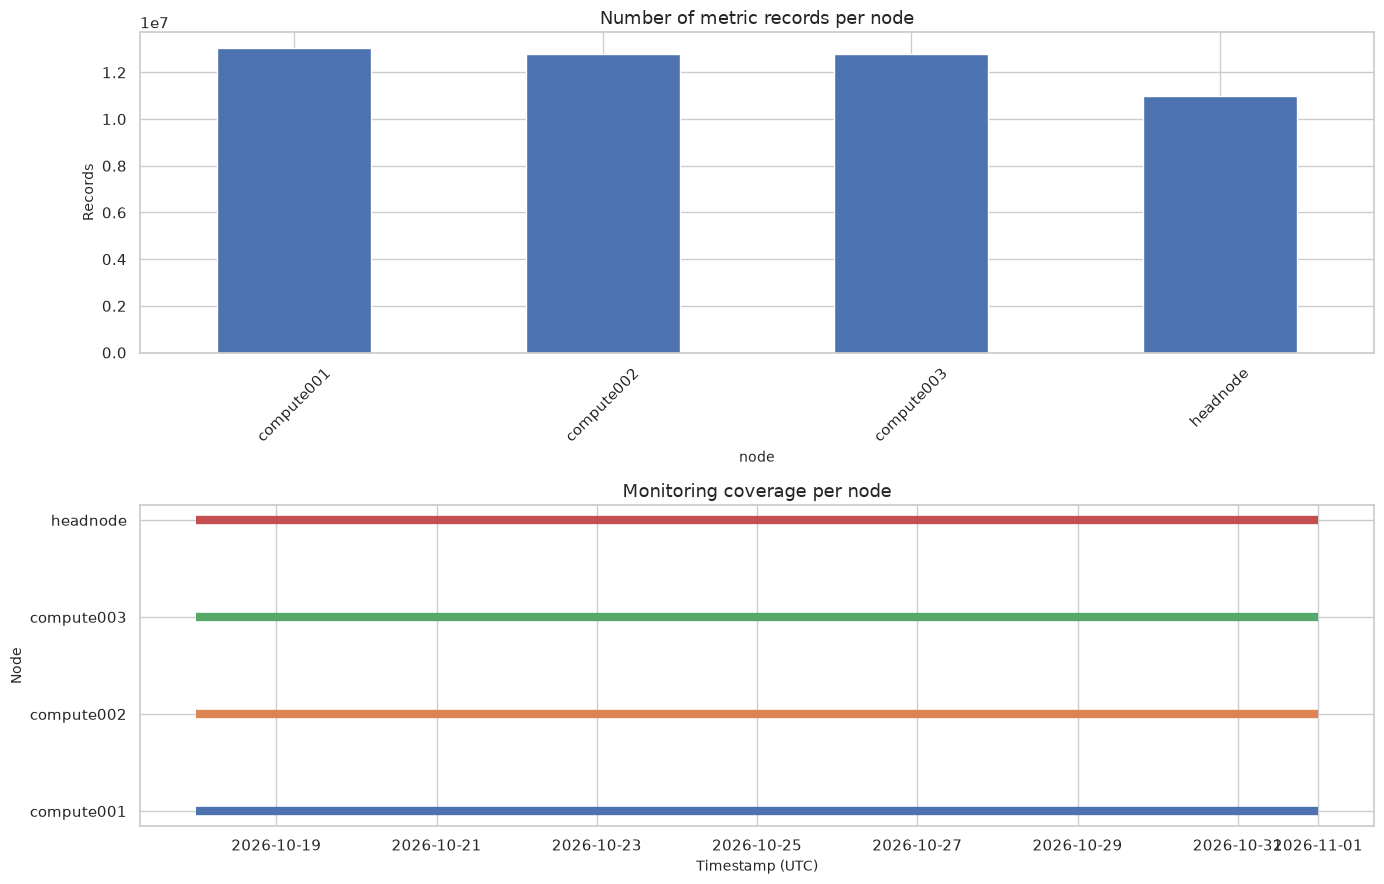

In [13]:
# Monitoring coverage per HPC node

import pandas as pd
import matplotlib.pyplot as plt

# Correct Unix timestamp conversion: seconds, not nanoseconds
node_time = pd.DataFrame({
    "node": df_raw["node_id"].astype("string"),
    "timestamp": pd.to_datetime(
        df_raw["timestamp"],
        unit="s",
        utc=True,
        errors="coerce"
    )
}).dropna()

# Calculate monitoring coverage
node_coverage = node_time.groupby("node").agg(
    records=("timestamp", "size"),
    first_seen=("timestamp", "min"),
    last_seen=("timestamp", "max"),
    distinct_timestamps=("timestamp", "nunique")
)

node_coverage["duration_hours"] = (
    node_coverage["last_seen"] - node_coverage["first_seen"]
).dt.total_seconds() / 3600

display(node_coverage.sort_values("records", ascending=False))

# Visualisation
fig, axes = plt.subplots(2, 1, figsize=(14, 9))

node_coverage["records"].sort_values(ascending=False).plot(
    kind="bar",
    ax=axes[0],
    title="Number of metric records per node"
)

axes[0].set_ylabel("Records")
axes[0].tick_params(axis="x", rotation=45)

for node, row in node_coverage.iterrows():
    axes[1].plot(
        [row["first_seen"], row["last_seen"]],
        [str(node), str(node)],
        linewidth=6,
        solid_capstyle="butt"
    )

axes[1].set_title("Monitoring coverage per node")
axes[1].set_xlabel("Timestamp (UTC)")
axes[1].set_ylabel("Node")

plt.tight_layout()
plt.show()

## 12. Distribution plots for numeric metrics

Histograms and boxplots help reveal skewness, multimodality and extreme observations. They do not determine whether a value is erroneous or anomalous.

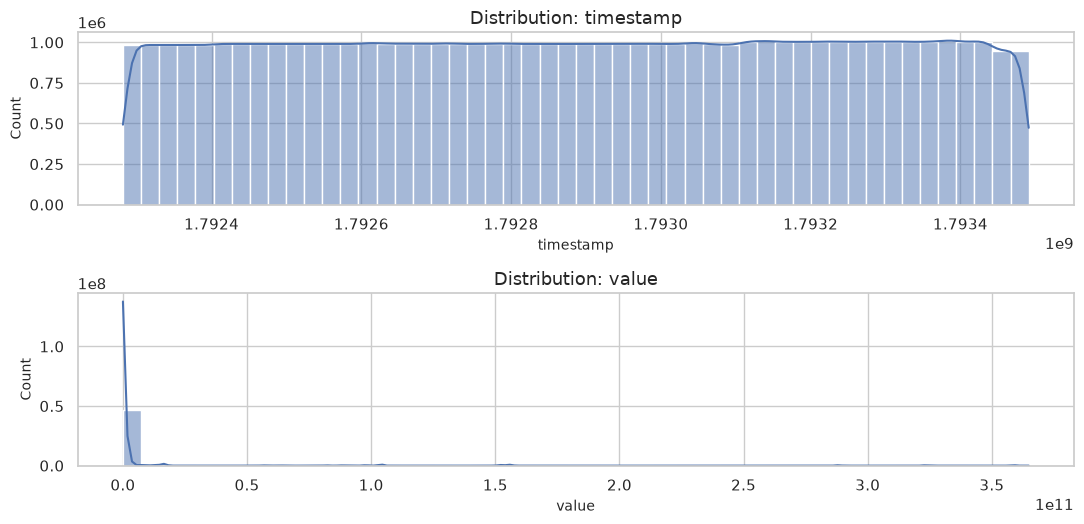

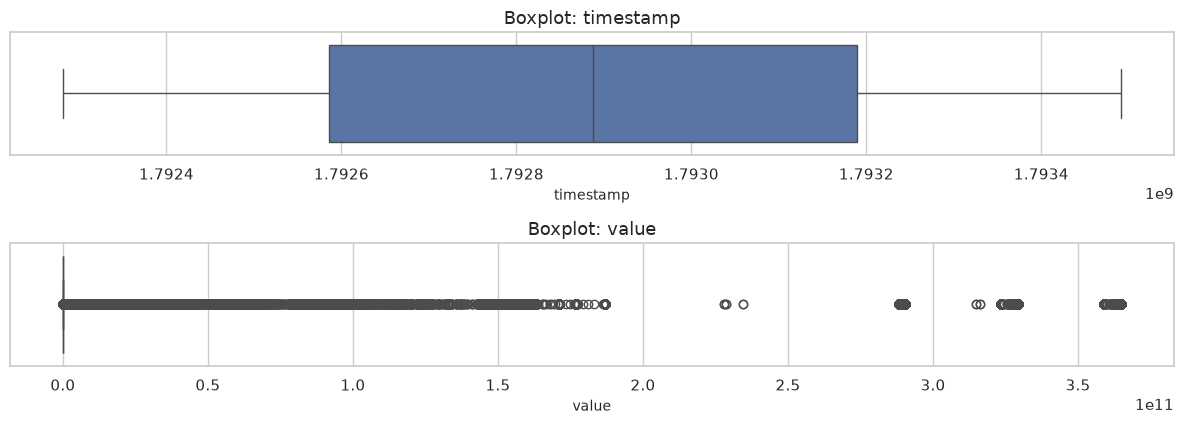

In [14]:
if numeric_cols:
    # Histograms
    for start in range(0, len(numeric_cols), 6):
        cols = numeric_cols[start:start+6]
        n = len(cols)
        fig, axes = plt.subplots(n, 1, figsize=(11, max(3, 2.7*n)))
        if n == 1:
            axes = [axes]
        for ax, col in zip(axes, cols):
            values = df_raw[col].replace([np.inf, -np.inf], np.nan).dropna()
            if len(values):
                sns.histplot(values, bins=50, kde=(len(values) > 20), ax=ax)
            ax.set_title(f"Distribution: {col}")
        plt.tight_layout()
        plt.show()

    # Boxplots on raw numeric scales; each metric is shown separately.
    for start in range(0, len(numeric_cols), 6):
        cols = numeric_cols[start:start+6]
        fig, axes = plt.subplots(len(cols), 1, figsize=(12, max(3, 2.2*len(cols))))
        if len(cols) == 1:
            axes = [axes]
        for ax, col in zip(axes, cols):
            values = df_raw[col].replace([np.inf, -np.inf], np.nan).dropna()
            if len(values):
                sns.boxplot(x=values, ax=ax)
            ax.set_title(f"Boxplot: {col}")
        plt.tight_layout()
        plt.show()
else:
    print("No numeric columns available for distribution plots.")

## 13. Potential extreme values (IQR screening only)

This section counts values outside the conventional 1.5 × IQR fences for each numeric metric. These are **candidate extremes**, not confirmed anomalies. Do not remove them automatically: rare events may be precisely what the research needs to detect.

In [15]:
# IQR screening must be performed within each metric because `value` contains
# different units and scales. This flags candidates only; it does not remove them.
iqr_rows = []

for metric_name, series in df_raw.groupby("metric", sort=False)["value"]:
    values = series.dropna()
    if values.empty:
        continue
    q1, q3 = values.quantile([0.25, 0.75])
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    count = int(((values < lower) | (values > upper)).sum())

    iqr_rows.append({
        "metric": metric_name,
        "q1": q1,
        "q3": q3,
        "iqr": iqr,
        "lower_fence": lower,
        "upper_fence": upper,
        "candidate_extreme_count": count,
        "candidate_extreme_percent": count / len(values) * 100
    })

iqr_summary = pd.DataFrame(iqr_rows).sort_values(
    "candidate_extreme_percent", ascending=False
)
display(iqr_summary.round(5))
print("Reminder: IQR candidates are not automatically anomalies or bad data.")

,metric,q1,q3,iqr,lower_fence,upper_fence,candidate_extreme_count,candidate_extreme_percent
11,node_disk_read_bytes_total,6.160154e+08,9.282048e+08,3.121894e+08,1.477312e+08,1.396489e+09,106945,27.08072
6,node_memory_MemTotal_bytes,1.679408e+10,1.679408e+10,0.000000e+00,1.679408e+10,1.679408e+10,80632,24.99876
0,node_cpu_seconds_total,3.400000e-01,1.936400e+02,1.933000e+02,-2.896100e+02,4.835900e+02,3551353,19.66137
16,node_network_transmit_bytes_total,5.260000e+02,3.119549e+09,3.119549e+09,-4.679322e+09,7.798872e+09,203534,19.54089
15,node_network_receive_bytes_total,5.600000e+01,5.622001e+09,5.622001e+09,-8.433001e+09,1.405500e+10,200332,19.23347
2,node_load5,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,61610,19.10127
1,node_load1,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,47418,14.70125
21,node_netstat_Tcp_RetransSegs,2.100000e+01,8.511000e+03,8.490000e+03,-1.271400e+04,2.124600e+04,36419,11.29117
4,node_procs_running,1.000000e+00,1.000000e+00,0.000000e+00,1.000000e+00,1.000000e+00,36220,11.22948
13,node_disk_io_time_seconds_total,2.394480e+02,1.104226e+03,8.647780e+02,-1.057719e+03,2.401393e+03,43838,11.10070


Reminder: IQR candidates are not automatically anomalies or bad data.


## 14. Correlation analysis

Correlation can reveal relationships between metrics, such as CPU utilisation and load, or memory usage and available memory. Correlation does not establish causation. Pairwise correlation uses available values and may be affected by missingness or workload mix.

In [16]:
print("Global correlation on the raw long-format `value` column is intentionally skipped.")
print("Reason: rows represent different Prometheus metrics with different units,")
print("and the data must first be aligned by timestamp and metric series.")
print("A valid correlation analysis will be performed later on a carefully selected")
print("wide-format feature table with one row per node and timestamp.")

Global correlation on the raw long-format `value` column is intentionally skipped.
Reason: rows represent different Prometheus metrics with different units,
and the data must first be aligned by timestamp and metric series.
A valid correlation analysis will be performed later on a carefully selected
wide-format feature table with one row per node and timestamp.


## 15. Time-series visualisation of metrics

Plot selected numeric metrics over time, including separate lines by node when possible. The plots are intended to reveal workload phases, gradual drift, spikes, periodic patterns and gaps.

To avoid unreadable plots, this section selects up to 8 metrics based on common HPC metric names. If none match, it uses the first numeric columns.

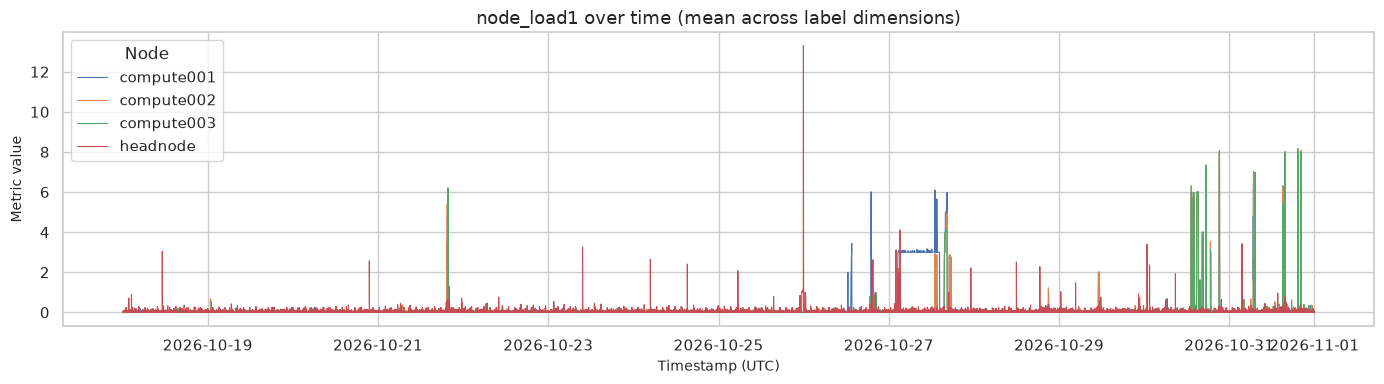

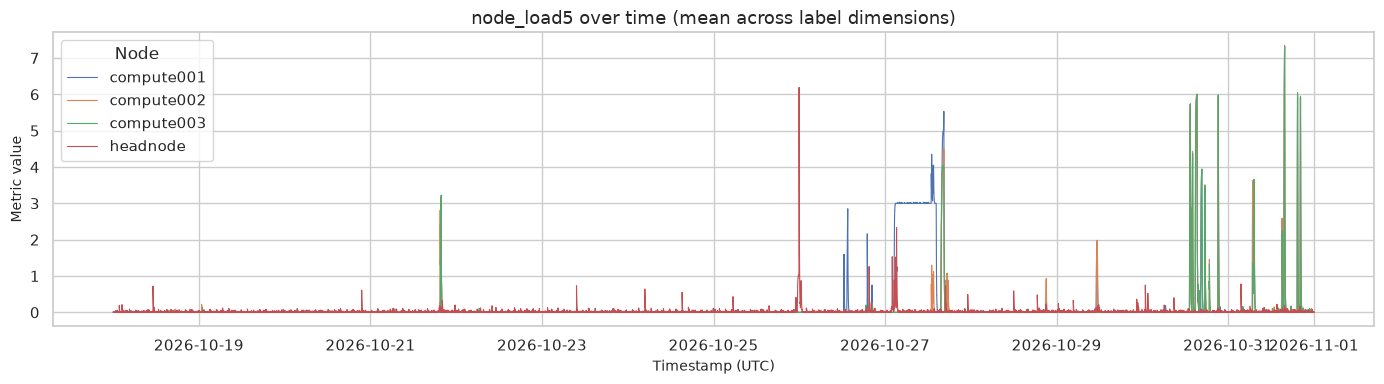

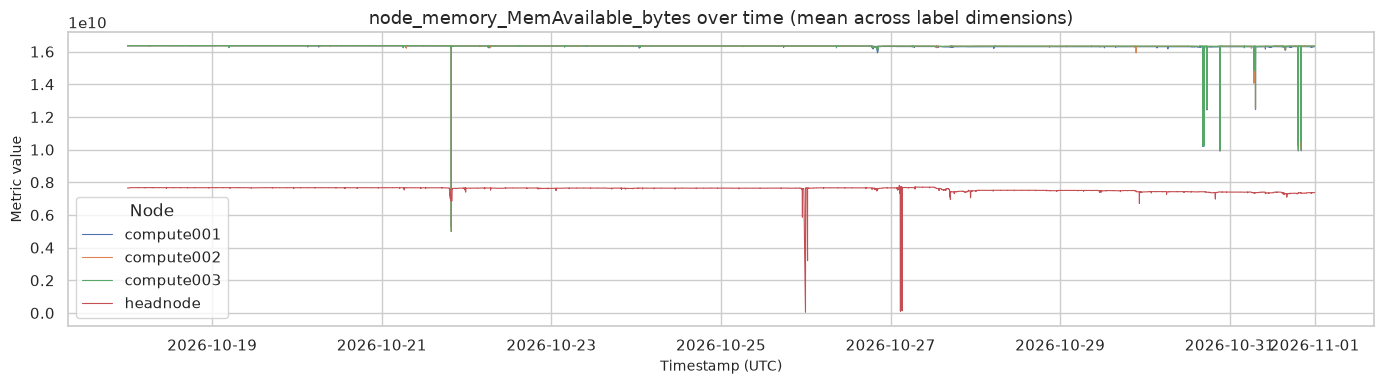

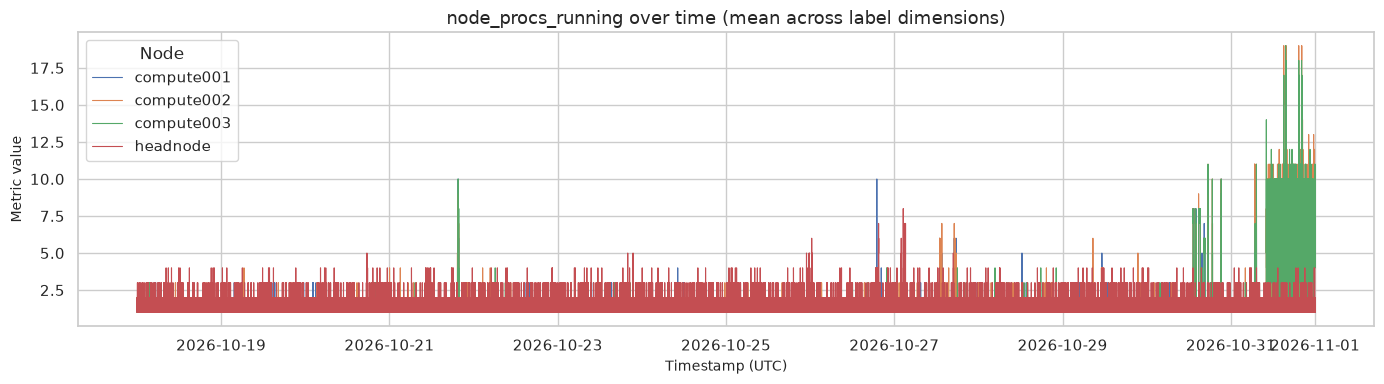

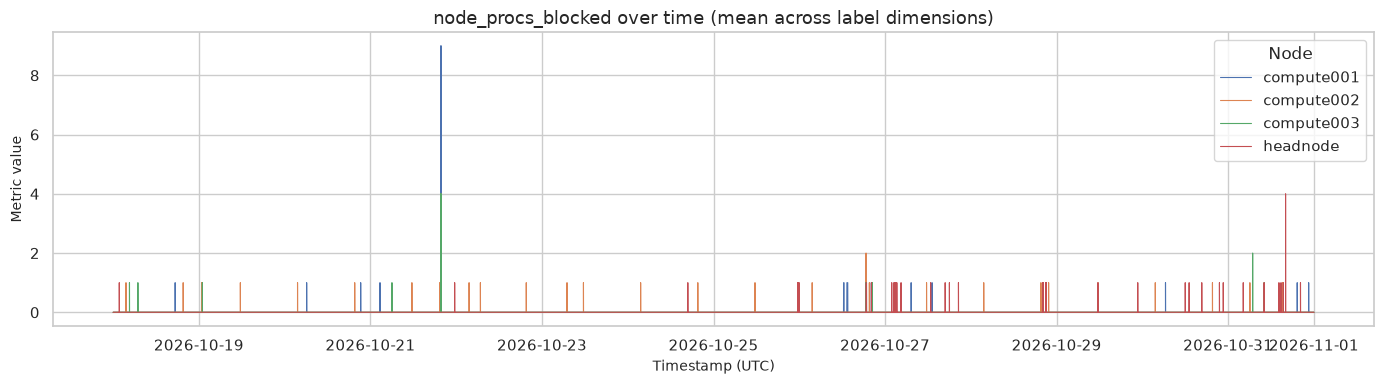

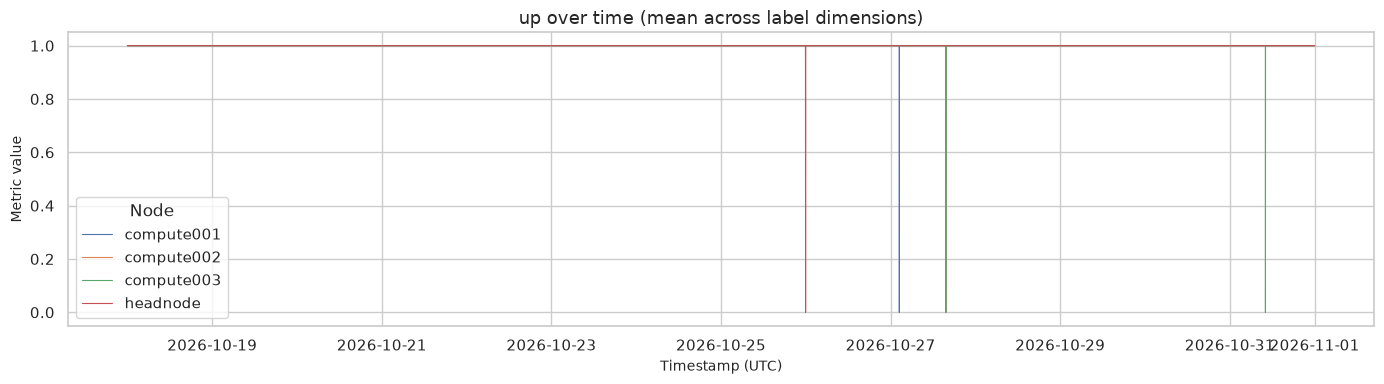

In [17]:
if "timestamp" in df_raw.columns and {"node_id", "metric", "value"}.issubset(df_raw.columns):
    # Plot a small set of meaningful metrics separately. Aggregate multiple
    # label series (e.g., CPU cores/interfaces) to node + timestamp for readability.
    preferred_metrics = [
        "node_load1",
        "node_load5",
        "node_memory_MemAvailable_bytes",
        "node_procs_running",
        "node_procs_blocked",
        "up"
    ]
    available_metrics = set(df_raw["metric"].dropna().unique())
    selected_metrics = [m for m in preferred_metrics if m in available_metrics][:6]

    if not selected_metrics:
        selected_metrics = df_raw["metric"].value_counts().head(4).index.tolist()

    for metric_name in selected_metrics:
        metric_data = df_raw.loc[
            df_raw["metric"].eq(metric_name),
            ["timestamp", "node_id", "value"]
        ]
        metric_data = metric_data.groupby(
            ["node_id", "timestamp"], as_index=False
        )["value"].mean()
        metric_data["timestamp_utc"] = pd.to_datetime(
            metric_data["timestamp"], unit="s", utc=True
        )

        plt.figure(figsize=(14, 4))
        for node, group in metric_data.groupby("node_id"):
            group = group.sort_values("timestamp_utc")
            plt.plot(group["timestamp_utc"], group["value"],
                     label=str(node), linewidth=0.8)
        plt.title(f"{metric_name} over time (mean across label dimensions)")
        plt.xlabel("Timestamp (UTC)")
        plt.ylabel("Metric value")
        plt.legend(title="Node")
        plt.tight_layout()
        plt.show()
else:
    print("Required timestamp, node_id, metric and value columns are unavailable.")

## 16. Event, status and label inspection

For predictive failure modelling, event and label fields are especially important. This cell searches for likely event, failure, anomaly, status, label and target columns and displays their value distributions.

Do not assume that an `event` or `label` column is a ground-truth failure label until its definition and provenance have been verified.

In [18]:
label_event_tokens = [
    "event", "failure", "fail", "anomaly", "label", "target",
    "status", "state", "incident", "fault", "maintenance", "error"
]
candidate_event_label_cols = [
    c for c in df_raw.columns
    if any(token in str(c).lower() for token in label_event_tokens)
]

print("Potential event/status/label columns:")
print(candidate_event_label_cols)

for col in candidate_event_label_cols:
    print(f"\n{col}:")
    print("Unique values:", df_raw[col].nunique(dropna=True))
    display(df_raw[col].value_counts(dropna=False).head(50).to_frame("count"))

Potential event/status/label columns:
['labels']

labels:
Unique values: 638


,count
labels,
__name__=up|instance=127.0.0.1:9100|job=node-exporter,80640
__name__=scrape_duration_seconds|instance=127.0.0.1:9100|job=node-exporter,80640
__name__=up|instance=10.100.0.167:9100|job=node-exporter,80639
__name__=up|instance=10.100.0.198:9100|job=node-exporter,80639
__name__=up|instance=10.100.0.66:9100|job=node-exporter,80639
__name__=scrape_duration_seconds|instance=10.100.0.167:9100|job=node-exporter,80639
__name__=scrape_duration_seconds|instance=10.100.0.198:9100|job=node-exporter,80639
__name__=scrape_duration_seconds|instance=10.100.0.66:9100|job=node-exporter,80639
__name__=node_cpu_seconds_total|cpu=0|instance=10.100.0.167:9100|job=node-exporter|mode=idle,80638


## 17. Metric behaviour by node

Compare distributions of selected metrics across nodes. Large differences may reflect hardware differences, different workloads, different roles, sensor issues or data-collection problems. They should be investigated before pooling all nodes into one model.

Metrics selected for node comparison: ['timestamp', 'value']


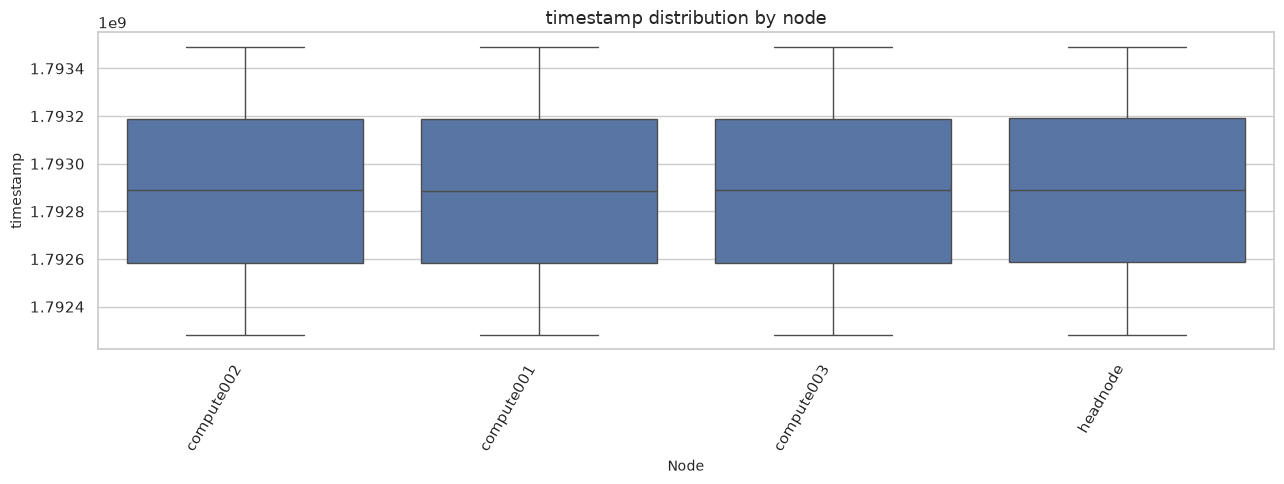

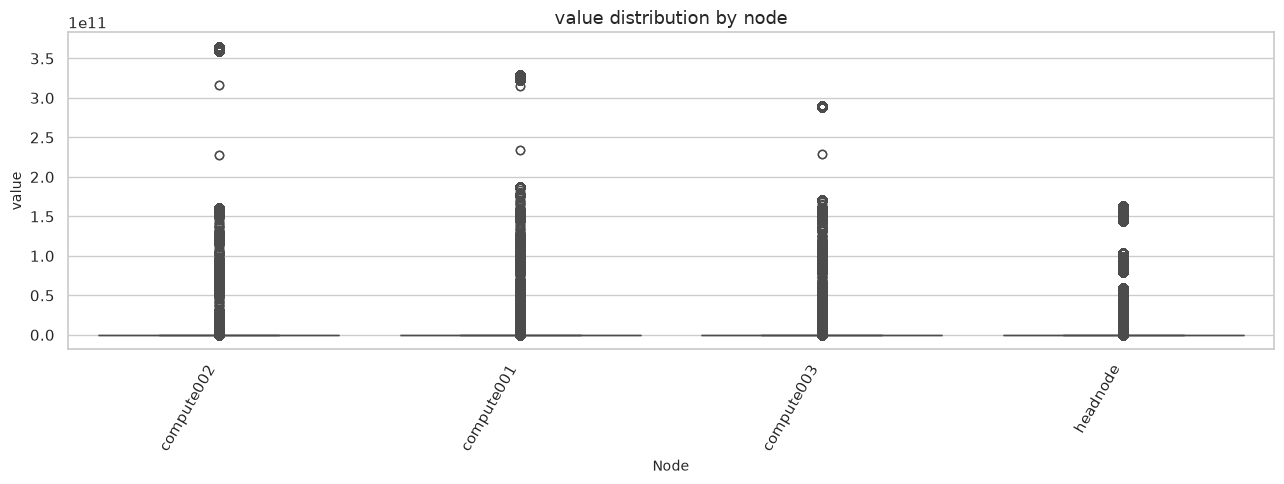

In [19]:
if node_candidates and numeric_cols:
    node_col = node_candidates[0]
    preferred = [
        c for c in numeric_cols
        if any(token in str(c).lower() for token in [
            "cpu_util", "memory_used", "load1", "disk_io",
            "network_errors", "temperature"
        ])
    ][:6]
    if not preferred:
        preferred = numeric_cols[:min(6, len(numeric_cols))]

    print("Metrics selected for node comparison:", preferred)

    for metric in preferred:
        plt.figure(figsize=(13, 5))
        sns.boxplot(data=df_raw, x=node_col, y=metric)
        plt.title(f"{metric} distribution by node")
        plt.xlabel("Node")
        plt.ylabel(metric)
        plt.xticks(rotation=60, ha="right")
        plt.tight_layout()
        plt.show()
else:
    print("Need a node identifier and numeric metrics for node comparisons.")

## 18. Prometheus metric inventory and metric-type classification

The dataset is in long format: each row is one observation of one labelled Prometheus time series.
This section inventories metrics and classifies them heuristically as counters, gauges, histogram buckets,
or unknown. The classification is based on metric naming conventions and must be checked against the
Prometheus metric definitions where available.

Counter metrics generally require rate/delta calculations. Gauge metrics are instantaneous values.
Do not calculate a single distribution or correlation across all metric values.

In [20]:
metric_inventory = (
    df_raw.groupby("metric")
    .agg(
        rows=("value", "size"),
        label_series=("labels", "nunique"),
        nodes=("node_id", "nunique"),
        first_epoch=("timestamp", "min"),
        last_epoch=("timestamp", "max"),
        missing_values=("value", lambda s: int(s.isna().sum()))
    )
    .reset_index()
)

def classify_prometheus_metric(name):
    name = str(name)
    if name.endswith("_bucket"):
        return "Histogram bucket (heuristic)"
    if name.endswith("_sum") or name.endswith("_count"):
        return "Summary/Histogram component (verify)"
    if name.endswith("_total"):
        return "Counter (heuristic)"
    return "Gauge or other (verify)"

metric_inventory["heuristic_type"] = metric_inventory["metric"].map(
    classify_prometheus_metric
)
metric_inventory["first_seen_utc"] = pd.to_datetime(
    metric_inventory["first_epoch"], unit="s", utc=True
)
metric_inventory["last_seen_utc"] = pd.to_datetime(
    metric_inventory["last_epoch"], unit="s", utc=True
)
metric_inventory = metric_inventory.drop(
    columns=["first_epoch", "last_epoch"]
).sort_values("rows", ascending=False)

display(metric_inventory)

print("\nMetric type counts:")
display(metric_inventory["heuristic_type"].value_counts().to_frame("metric_count"))

print("\nUnique nodes:")
display(df_raw["node_id"].value_counts().rename("rows").to_frame())

print("\nUnique metric-label series per metric:")
series_counts = (
    df_raw[["metric", "labels"]].drop_duplicates()
    .groupby("metric").size().sort_values(ascending=False)
    .rename("unique_label_series").to_frame()
)
display(series_counts)

,metric,rows,label_series,nodes,missing_values,heuristic_type,first_seen_utc,last_seen_utc
0,node_cpu_seconds_total,18062592,224,4,0,Counter (heuristic),2026-10-18 00:00:04.335999966+00:00,2026-10-31 23:59:58.588000059+00:00
24,node_scrape_collector_success,15777920,198,4,0,Gauge or other (verify),2026-10-18 00:00:04.335999966+00:00,2026-10-31 23:59:58.588000059+00:00
5,node_filesystem_avail_bytes,1876918,33,4,0,Gauge or other (verify),2026-10-18 00:00:04.335999966+00:00,2026-10-31 23:59:58.588000059+00:00
6,node_filesystem_size_bytes,1876918,33,4,0,Gauge or other (verify),2026-10-18 00:00:04.335999966+00:00,2026-10-31 23:59:58.588000059+00:00
18,node_network_receive_errs_total,1041580,13,4,0,Counter (heuristic),2026-10-18 00:00:04.335999966+00:00,2026-10-31 23:59:58.588000059+00:00
21,node_network_transmit_errs_total,1041580,13,4,0,Counter (heuristic),2026-10-18 00:00:04.335999966+00:00,2026-10-31 23:59:58.588000059+00:00
19,node_network_transmit_bytes_total,1041580,13,4,0,Counter (heuristic),2026-10-18 00:00:04.335999966+00:00,2026-10-31 23:59:58.588000059+00:00
17,node_network_receive_drop_total,1041580,13,4,0,Counter (heuristic),2026-10-18 00:00:04.335999966+00:00,2026-10-31 23:59:58.588000059+00:00
16,node_network_receive_bytes_total,1041580,13,4,0,Counter (heuristic),2026-10-18 00:00:04.335999966+00:00,2026-10-31 23:59:58.588000059+00:00
20,node_network_transmit_drop_total,1041580,13,4,0,Counter (heuristic),2026-10-18 00:00:04.335999966+00:00,2026-10-31 23:59:58.588000059+00:00



Metric type counts:


,metric_count
heuristic_type,
Gauge or other (verify),17
Counter (heuristic),10



Unique nodes:


,rows
node_id,
compute001,13061640
compute002,12789782
compute003,12789104
headnode,10976048



Unique metric-label series per metric:


,unique_label_series
metric,
node_cpu_seconds_total,224
node_scrape_collector_success,198
node_filesystem_avail_bytes,33
node_filesystem_size_bytes,33
node_network_receive_errs_total,13
node_network_transmit_errs_total,13
node_network_transmit_bytes_total,13
node_network_receive_drop_total,13
node_network_receive_bytes_total,13


## 19. Focused analysis: 21 October 2026 `stress-ng` experiment

**User-provided experimental context:** a controlled `stress-ng` stress test was run on 21 October 2026
between 19:00 and 20:00 South African Standard Time (SAST, UTC+2), stressing CPU, disk and network
interface resources. The exact command, worker counts, stress methods and target nodes are not currently
documented. This is a known stress-test period, not a confirmed failure.

The analysis compares:
- Before: 18:00–19:00 SAST (16:00–17:00 UTC)
- During: 19:00–20:00 SAST (17:00–18:00 UTC)
- After: 20:00–21:00 SAST (18:00–19:00 UTC)

The raw Parquet data is not changed. Counter metrics are converted to per-second rates within the
selected three-hour window; negative counter differences (possible resets) are excluded from rates.
The analysis will only report metrics actually present in the dataset.

In [22]:

print("===== DATAFRAME COLUMN DIAGNOSTICS =====")

for name, frame in [
    ("gauge_data", gauge_data),
    ("derived_data", derived_data)
]:
    print(f"\n{name}")
    print("Shape:", frame.shape)
    print("Columns:", frame.columns.tolist())

    duplicates = frame.columns[
        frame.columns.duplicated(keep=False)
    ].tolist()

    print("Duplicate columns:", duplicates)

print("\n===== ORIGINAL DATASET COLUMNS =====")
print("Columns:", df_raw.columns.tolist())

print(
    "Original duplicate columns:",
    df_raw.columns[
        df_raw.columns.duplicated(keep=False)
    ].tolist()
)


===== DATAFRAME COLUMN DIAGNOSTICS =====

gauge_data
Shape: (28800, 4)
Columns: ['node_id', 'timestamp', 'metric', 'value']
Duplicate columns: []

derived_data
Shape: (31636, 5)
Columns: ['timestamp', 'node_id', 'metric', 'value', 'value']
Duplicate columns: ['value', 'value']

===== ORIGINAL DATASET COLUMNS =====
Columns: ['timestamp', 'node_id', 'metric', 'labels', 'value']
Original duplicate columns: []


In [24]:
print("===== INDIVIDUAL DERIVED FRAMES =====")

for i, frame in enumerate(derived_frames):
    print(f"\nFrame {i}")
    print("Shape:", frame.shape)
    print("Columns:", frame.columns.tolist())
    print(
        "Duplicate columns:",
        frame.columns[frame.columns.duplicated(keep=False)].tolist()
    )
    print(frame.head(3))

===== INDIVIDUAL DERIVED FRAMES =====

Frame 0
Shape: (2876, 4)
Columns: ['node_id', 'timestamp', 'cpu_busy_percent', 'metric']
Duplicate columns: []
      node_id     timestamp  cpu_busy_percent                    metric
0  compute001  1.792598e+09          0.008333  derived_cpu_busy_percent
1  compute001  1.792598e+09          0.008334  derived_cpu_busy_percent
2  compute001  1.792598e+09          0.033331  derived_cpu_busy_percent

Frame 1
Shape: (2876, 4)
Columns: ['node_id', 'timestamp', 'value', 'metric']
Duplicate columns: []
      node_id     timestamp  value                      metric
0  compute001  1.792598e+09    0.0  disk_read_bytes_per_second
1  compute001  1.792598e+09    0.0  disk_read_bytes_per_second
2  compute001  1.792598e+09    0.0  disk_read_bytes_per_second

Frame 2
Shape: (2876, 4)
Columns: ['node_id', 'timestamp', 'value', 'metric']
Duplicate columns: []
      node_id     timestamp  value                       metric
0  compute001  1.792598e+09    0.0  disk_wri

In [21]:

import re
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# ============================================================
# 1. DEFINE THE STRESS-TEST ANALYSIS WINDOWS
# ============================================================

STRESS_DATE = "2026-10-21"

# SAST is UTC+2.
# User-reported stress period: 19:00-20:00 SAST
# Equivalent UTC period: 17:00-18:00 UTC.

stress_windows_utc = {
    "Before": (
        pd.Timestamp(f"{STRESS_DATE} 16:00:00", tz="UTC"),
        pd.Timestamp(f"{STRESS_DATE} 17:00:00", tz="UTC")
    ),
    "During": (
        pd.Timestamp(f"{STRESS_DATE} 17:00:00", tz="UTC"),
        pd.Timestamp(f"{STRESS_DATE} 18:00:00", tz="UTC")
    ),
    "After": (
        pd.Timestamp(f"{STRESS_DATE} 18:00:00", tz="UTC"),
        pd.Timestamp(f"{STRESS_DATE} 19:00:00", tz="UTC")
    )
}

stress_start_epoch = stress_windows_utc["Before"][0].timestamp()
stress_end_epoch = stress_windows_utc["After"][1].timestamp()


# ============================================================
# 2. EXTRACT THE THREE-HOUR ANALYSIS WINDOW
# ============================================================

stress_mask = df_raw["timestamp"].between(
    stress_start_epoch,
    stress_end_epoch,
    inclusive="both"
)

stress_raw = df_raw.loc[
    stress_mask,
    ["timestamp", "node_id", "metric", "labels", "value"]
].copy()


if stress_raw.empty:

    print("No observations found in the 21 October 2026 analysis window.")
    print("Check the dataset coverage and timestamp interpretation.")

else:

    stress_raw["timestamp_utc"] = pd.to_datetime(
        stress_raw["timestamp"],
        unit="s",
        utc=True
    )

    print("Rows in three-hour event window:", f"{len(stress_raw):,}")
    print(
        "Nodes represented:",
        sorted(stress_raw["node_id"].dropna().unique())
    )
    print(
        "Metrics represented:",
        stress_raw["metric"].nunique()
    )

    print("\nUTC analysis windows:")

    for phase, (start, end) in stress_windows_utc.items():
        print(f"  {phase}: {start} to {end}")


    # ========================================================
    # 3. ASSIGN OBSERVATIONS TO EXPERIMENT PHASES
    # ========================================================

    def phase_for_epoch(epoch):

        for phase, (start, end) in stress_windows_utc.items():

            if start.timestamp() <= epoch < end.timestamp():
                return phase

        return None


    stress_raw["phase"] = stress_raw["timestamp"].map(
        phase_for_epoch
    )


    # ========================================================
    # 4. EXTRACT PROMETHEUS LABEL VALUES
    # ========================================================

    def get_label(label_text, key):

        match = re.search(
            r"(?:^|\|)" + re.escape(key) + r"=([^|]*)",
            str(label_text)
        )

        return match.group(1) if match else None


    stress_raw["mode"] = stress_raw["labels"].map(
        lambda x: get_label(x, "mode")
    )

    stress_raw["cpu"] = stress_raw["labels"].map(
        lambda x: get_label(x, "cpu")
    )


    # ========================================================
    # 5. IDENTIFY COUNTER METRICS
    # ========================================================

    # Counters are cumulative.
    # We calculate their per-second rates using consecutive
    # observations from the same node, metric and label set.

    counter_metrics = [
        "node_cpu_seconds_total",
        "node_disk_read_bytes_total",
        "node_disk_written_bytes_total",
        "node_disk_io_time_seconds_total",
        "node_network_receive_bytes_total",
        "node_network_transmit_bytes_total",
        "node_network_receive_errs_total",
        "node_network_transmit_errs_total",
        "node_network_receive_drop_total",
        "node_network_transmit_drop_total",
        "node_netstat_Tcp_RetransSegs"
    ]


    counter_present = [
        metric
        for metric in counter_metrics
        if metric in set(stress_raw["metric"].dropna())
    ]


    counter_data = stress_raw[
        stress_raw["metric"].isin(counter_present)
    ].copy()


    # ========================================================
    # 6. CALCULATE COUNTER RATES
    # ========================================================

    if not counter_data.empty:

        counter_data = counter_data.sort_values(
            ["node_id", "metric", "labels", "timestamp"]
        )

        counter_group = counter_data.groupby(
            ["node_id", "metric", "labels"],
            sort=False
        )

        counter_data["delta_value"] = (
            counter_group["value"].diff()
        )

        counter_data["delta_seconds"] = (
            counter_group["timestamp"].diff()
        )

        # Exclude counter resets, negative deltas and
        # non-positive time intervals.

        valid_rate = (
            counter_data["delta_value"].ge(0) &
            counter_data["delta_seconds"].gt(0)
        )

        counter_data["rate_per_second"] = np.where(
            valid_rate,
            counter_data["delta_value"] /
            counter_data["delta_seconds"],
            np.nan
        )

    else:

        counter_data = pd.DataFrame()


    # ========================================================
    # 7. DERIVE NODE-LEVEL CPU BUSY PERCENTAGE
    # ========================================================

    derived_frames = []


    if (
        not counter_data.empty
        and "node_cpu_seconds_total" in counter_data["metric"].values
    ):

        cpu_rates = counter_data[
            counter_data["metric"].eq("node_cpu_seconds_total")
        ].dropna(
            subset=["rate_per_second"]
        ).copy()


        if not cpu_rates.empty:

            # Aggregate CPU mode rates across CPU cores.
            cpu_mode_rates = (
                cpu_rates.groupby(
                    ["node_id", "timestamp", "mode"]
                )["rate_per_second"]
                .sum()
                .unstack("mode", fill_value=0)
            )

            mode_columns = list(cpu_mode_rates.columns)

            total_rate = cpu_mode_rates[mode_columns].sum(axis=1)

            idle_rate = (
                cpu_mode_rates["idle"]
                if "idle" in cpu_mode_rates.columns
                else 0
            )

            # CPU busy percentage:
            # 100 * (total CPU rate - idle CPU rate) / total CPU rate

            cpu_busy = (
                100 *
                (total_rate - idle_rate) /
                total_rate.replace(0, np.nan)
            )

            # IMPORTANT FIX:
            # Rename to 'value' BEFORE appending the frame.
            cpu_busy = cpu_busy.rename("value").reset_index()

            cpu_busy["metric"] = "derived_cpu_busy_percent"

            derived_frames.append(cpu_busy)


    # ========================================================
    # 8. DERIVE DISK AND NETWORK COUNTER FEATURES
    # ========================================================

    rate_metric_map = {

        "node_disk_read_bytes_total":
            "disk_read_bytes_per_second",

        "node_disk_written_bytes_total":
            "disk_write_bytes_per_second",

        "node_disk_io_time_seconds_total":
            "disk_io_time_rate_sum",

        "node_network_receive_bytes_total":
            "network_receive_bytes_per_second",

        "node_network_transmit_bytes_total":
            "network_transmit_bytes_per_second",

        "node_network_receive_errs_total":
            "network_receive_errors_per_second",

        "node_network_transmit_errs_total":
            "network_transmit_errors_per_second",

        "node_network_receive_drop_total":
            "network_receive_drops_per_second",

        "node_network_transmit_drop_total":
            "network_transmit_drops_per_second",

        "node_netstat_Tcp_RetransSegs":
            "tcp_retransmissions_per_second"
    }


    if not counter_data.empty:

        for source_metric, derived_name in rate_metric_map.items():

            part = counter_data[
                counter_data["metric"].eq(source_metric)
            ].dropna(
                subset=["rate_per_second"]
            )


            if not part.empty:

                # Aggregate rates across device/interface labels.
                agg = (
                    part.groupby(
                        ["node_id", "timestamp"]
                    )["rate_per_second"]
                    .sum()
                    .rename("value")
                    .reset_index()
                )

                agg["metric"] = derived_name

                derived_frames.append(agg)


    # ========================================================
    # 9. SELECT AVAILABLE GAUGE METRICS
    # ========================================================

    # Gauges represent instantaneous measurements rather
    # than cumulative counters.

    gauge_candidates = [

        "node_load1",
        "node_load5",
        "node_load15",

        "node_procs_running",
        "node_procs_blocked",

        "node_memory_MemAvailable_bytes",
        "node_memory_MemFree_bytes",

        "node_filesystem_avail_bytes",

        "node_disk_io_now",

        "up"
    ]


    gauge_present = [
        metric
        for metric in gauge_candidates
        if metric in set(stress_raw["metric"].dropna())
    ]


    gauge_data = stress_raw[
        stress_raw["metric"].isin(gauge_present)
    ][
        ["timestamp", "node_id", "metric", "value"]
    ].copy()


    # Aggregate gauge dimensions by mean for node-level
    # trend comparison.

    if not gauge_data.empty:

        gauge_data = (
            gauge_data.groupby(
                ["node_id", "timestamp", "metric"],
                as_index=False
            )["value"]
            .mean()
        )


    # ========================================================
    # 10. STANDARDISE AND COMBINE DERIVED DATA
    # ========================================================

    # All derived frames must have the same four columns:
    # timestamp, node_id, metric, value.

    if derived_frames:

        derived_data = pd.concat(
            derived_frames,
            ignore_index=True,
            sort=False
        )

        # Select the standard schema.
        derived_data = derived_data[
            ["timestamp", "node_id", "metric", "value"]
        ].copy()

    else:

        derived_data = pd.DataFrame(
            columns=[
                "timestamp",
                "node_id",
                "metric",
                "value"
            ]
        )


    # Ensure gauge data uses the same schema.
    gauge_data = gauge_data[
        ["timestamp", "node_id", "metric", "value"]
    ].copy()


    # Combine gauge and derived measurements.
    analysis_data = pd.concat(
        [gauge_data, derived_data],
        ignore_index=True,
        sort=False
    )


    # ========================================================
    # 11. VALIDATE THE COMBINED DATA
    # ========================================================

    print("\n" + "=" * 60)
    print("DATAFRAME VALIDATION")
    print("=" * 60)

    print("\nGauge data shape:", gauge_data.shape)
    print("Derived data shape:", derived_data.shape)
    print("Combined data shape:", analysis_data.shape)

    print("\nCombined columns:")
    print(analysis_data.columns.tolist())

    duplicate_columns = analysis_data.columns[
        analysis_data.columns.duplicated(keep=False)
    ].tolist()

    print("\nDuplicate columns:", duplicate_columns)

    if duplicate_columns:
        raise ValueError(
            "Duplicate columns detected. Stop analysis and inspect "
            "the derived-data construction."
        )

    print("\nMissing values:")
    print(analysis_data.isna().sum())

    print("\nMetrics represented:")
    print(sorted(analysis_data["metric"].unique()))

    print("\nRows per node:")
    print(analysis_data.groupby("node_id").size())


    # ========================================================
    # 12. ASSIGN PHASES AND CONVERT TIMESTAMPS
    # ========================================================

    if not analysis_data.empty:

        analysis_data["phase"] = (
            analysis_data["timestamp"].map(phase_for_epoch)
        )

        # Remove observations outside the three defined phases.
        # This also excludes the final 19:00 UTC boundary.
        analysis_data = analysis_data.dropna(
            subset=["phase"]
        )

        analysis_data["timestamp_utc"] = pd.to_datetime(
            analysis_data["timestamp"],
            unit="s",
            utc=True
        )


        # ====================================================
        # 13. CALCULATE PHASE-LEVEL STATISTICS
        # ====================================================

        phase_summary = (
            analysis_data.groupby(
                ["node_id", "metric", "phase"]
            )["value"]
            .agg(
                observations="count",
                mean="mean",
                median="median",
                p95=lambda s: s.quantile(0.95),
                maximum="max"
            )
            .reset_index()
        )


        print("\n" + "=" * 60)
        print("BEFORE / DURING / AFTER PHASE SUMMARY")
        print("=" * 60)

        display(
            phase_summary.sort_values(
                ["metric", "node_id", "phase"]
            )
        )


        # ====================================================
        # 14. PLOT SELECTED METRIC TIME SERIES
        # ====================================================

        plot_metrics = [

            "derived_cpu_busy_percent",

            "disk_read_bytes_per_second",
            "disk_write_bytes_per_second",

            "network_receive_bytes_per_second",
            "network_transmit_bytes_per_second",

            "node_load1",

            "node_procs_running",
            "node_procs_blocked"
        ]


        plot_metrics = [
            metric
            for metric in plot_metrics
            if metric in set(analysis_data["metric"])
        ]


        for metric_name in plot_metrics:

            plt.figure(figsize=(14, 4))

            for node, group in analysis_data[
                analysis_data["metric"].eq(metric_name)
            ].groupby("node_id"):

                group = group.sort_values("timestamp_utc")

                plt.plot(
                    group["timestamp_utc"],
                    group["value"],
                    label=str(node),
                    linewidth=0.9
                )


            # Mark the beginning of each experiment phase.
            for phase, (start, end) in stress_windows_utc.items():

                plt.axvline(
                    start,
                    linestyle="--",
                    alpha=0.5,
                    label=f"{phase} start"
                )


            plt.title(
                f"{metric_name}: before, during and after stress-ng"
            )

            plt.xlabel("Timestamp (UTC)")
            plt.ylabel(metric_name)

            plt.legend(title="Node")
            plt.tight_layout()
            plt.show()


        # ====================================================
        # 15. PHASE COMPARISON BOXPLOTS
        # ====================================================

        for metric_name in plot_metrics:

            subset = analysis_data[
                analysis_data["metric"].eq(metric_name)
            ]

            if subset.empty:
                continue


            plt.figure(figsize=(8, 4))

            sns.boxplot(
                data=subset,
                x="phase",
                y="value",
                order=["Before", "During", "After"]
            )

            plt.title(
                f"{metric_name}: phase comparison"
            )

            plt.xlabel("Experiment phase")
            plt.ylabel(metric_name)

            plt.tight_layout()
            plt.show()


    else:

        print(
            "No selected gauge or counter-derived metrics "
            "were available for comparison."
        )


    # ========================================================
    # 16. INTERPRETATION SAFEGUARDS
    # ========================================================

    print("\n" + "=" * 60)
    print("INTERPRETATION SAFEGUARDS")
    print("=" * 60)

    print(
        "- A change during the stress window is evidence of a "
        "system response, not proof of a failure."
    )

    print(
        "- The exact stress-ng arguments and target nodes "
        "are not known."
    )

    print(
        "- Missing or negative counter deltas can occur at "
        "counter resets or scrape gaps."
    )

    print(
        "- This event is an annotated stress test, not a "
        "verified failure label."
    )

    print(
        "- CPU busy percentage is calculated from CPU counter "
        "rates; validate its magnitude before interpreting it."
    )

    print(
        "- The final timestamp boundary at 19:00 UTC is excluded "
        "from the three analysis phases."
    )


Rows in three-hour event window: 443,168
Nodes represented: ['compute001', 'compute002', 'compute003', 'headnode']
Metrics represented: 27
UTC analysis windows:
  Before: 2026-10-21 16:00:00+00:00 to 2026-10-21 17:00:00+00:00
  During: 2026-10-21 17:00:00+00:00 to 2026-10-21 18:00:00+00:00
  After: 2026-10-21 18:00:00+00:00 to 2026-10-21 19:00:00+00:00


InvalidIndexError: Reindexing only valid with uniquely valued Index objects

## 20. Automated raw-data quality observations

This section consolidates observations that should be reviewed before any cleaning or feature engineering. It does not make automatic decisions about whether records should be changed.

In [ ]:
quality_findings = []

quality_findings.append({
    "check": "Dataset dimensions",
    "observation": f"{df_raw.shape[0]:,} rows and {df_raw.shape[1]:,} columns"
})
quality_findings.append({
    "check": "Exact duplicate rows",
    "observation": f"{int(df_raw.duplicated().sum()):,}"
})
quality_findings.append({
    "check": "Columns containing missing values",
    "observation": f"{int((df_raw.isna().sum() > 0).sum())} of {df_raw.shape[1]}"
})
quality_findings.append({
    "check": "Total missing cells",
    "observation": f"{int(df_raw.isna().sum().sum()):,} ({df_raw.isna().mean().mean()*100:.4f}% of all cells)"
})
quality_findings.append({
    "check": "Numeric columns",
    "observation": str(len(numeric_cols))
})
quality_findings.append({
    "check": "Potential timestamp columns",
    "observation": ", ".join(map(str, timestamp_candidates)) if timestamp_candidates else "Not identified"
})
quality_findings.append({
    "check": "Potential node identifier columns",
    "observation": ", ".join(map(str, node_candidates)) if node_candidates else "Not identified"
})
quality_findings.append({
    "check": "Potential event/label columns",
    "observation": ", ".join(map(str, candidate_event_label_cols)) if candidate_event_label_cols else "Not identified"
})

display(pd.DataFrame(quality_findings))

## 21. Research suitability assessment

Use the observations above to answer these questions. Do not proceed to model training until the data's meaning and limitations are understood.

### A. Normal-behaviour learning
- Is there enough healthy data across idle, low, medium and high workload conditions?
- Are node identities and timestamps available?
- Are monitoring intervals sufficiently consistent?
- Are there differences between nodes that require separate models or node-aware features?

### B. Anomaly detection
- Are there known fault or incident records?
- Do the metrics contain enough temporal context to distinguish workload spikes from abnormal behaviour?
- Are extreme observations real events, sensor errors or collection artefacts?

### C. Failure prediction
- Is there a verified failure event timestamp for each failure?
- Can each node-time observation be labelled according to whether a failure occurs within a future horizon?
- Are there enough independent failure events to evaluate prediction reliably?
- Can we split the data chronologically without leaking information from the future?

### D. Data integrity
- Are missing values concentrated in particular nodes, periods or metrics?
- Are there duplicate node-timestamp records?
- Are there large monitoring gaps?
- Are metric units and definitions documented?

### Suggested next step
After reviewing the outputs, document the dataset's schema, monitoring coverage, data quality limitations, event-label provenance and suitability for each modelling objective. Only then should we create a separate cleaning and feature-engineering notebook.

## 22. Optional: export observation summaries

This section exports summary tables to a separate folder. It does not export or overwrite the original Parquet dataset. Run it only after the notebook has completed successfully.

In [ ]:
REPORT_DIR = DATA_PATH.parent / "hpc_dataset_observation"
REPORT_DIR.mkdir(exist_ok=True)

dtype_summary.to_csv(REPORT_DIR / "column_dtype_summary.csv", index=False)
missing_summary.to_csv(REPORT_DIR / "missing_values_summary.csv")
if numeric_cols:
    numeric_description.to_csv(REPORT_DIR / "numeric_descriptive_statistics.csv")
if "iqr_summary" in globals() and not iqr_summary.empty:
    iqr_summary.to_csv(REPORT_DIR / "iqr_extreme_value_screening.csv", index=False)
if "node_coverage" in globals():
    node_coverage.to_csv(REPORT_DIR / "node_time_coverage.csv")
if "corr_pairs" in globals() and not corr_pairs.empty:
    corr_pairs.to_csv(REPORT_DIR / "numeric_correlations.csv", index=False)

print("Observation summaries saved to:", REPORT_DIR)
print("Original Parquet file was not modified.")

---
## End of notebook

**This notebook deliberately stops before cleaning.** Preserve the raw dataset as the immutable source of truth. Any future cleaned dataset, engineered features, labels or model-ready tables should be saved as separate outputs with documented transformations.